<a href="https://colab.research.google.com/github/SherjinCruz/Exit-Examination-G1/blob/main/Exit_Examination_G1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Task 1 - Data Understanding and Exploration

In [690]:
# importing the modules
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [691]:
# loading the data

file = '/content/drive/MyDrive/DSA/Exit Examiniation - G1/G1.csv'
df = pd.read_csv(file)
df.head()

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both


In [692]:
# Identifing numerical and  categorical features

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Response_ID                         500 non-null    int64  
 1   Timestamp                           500 non-null    object 
 2   Age                                 478 non-null    object 
 3   Gender                              484 non-null    object 
 4   Occupation_Status                   479 non-null    object 
 5   Country_Region                      480 non-null    object 
 6   Monthly_Income_Range                479 non-null    object 
 7   Shop_Most_Where                     484 non-null    object 
 8   Online_Shopping_Frequency           481 non-null    object 
 9   Preferred_Platform                  486 non-null    object 
 10  Primary_Device                      492 non-null    object 
 11  Top_Spending_Category               476 non-n

In [693]:
# checking miising values
df.isnull().sum()

,0
Response_ID,0
Timestamp,0
Age,22
Gender,16
Occupation_Status,21
Country_Region,20
Monthly_Income_Range,21
Shop_Most_Where,16
Online_Shopping_Frequency,19
Preferred_Platform,14


In [694]:
# identifing dupicates

df.duplicated().sum()

np.int64(0)

In [695]:
# summary ststicics

df.describe()

,Response_ID,Review_Influence_Score,Social_Ads_Influence_Score,Price_Comparison_Frequency,Discount_Importance_Score,Likely_To_Buy_After_Ad_Score,Impulse_Purchase_Frequency,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency
count,500.000000,485.000000,479.000000,474.000000,477.000000,475.000000,484.000000,457.000000,450.000000,448.000000
mean,250.500000,3.053608,3.079332,4.139241,3.821803,3.016842,2.590909,7.126915,6.160000,2.187500
std,144.481833,1.128707,1.228144,0.943219,0.989284,1.109857,1.162741,1.592636,1.918425,0.902705
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,1.000000
25%,125.750000,2.000000,2.000000,4.000000,3.000000,2.000000,2.000000,6.000000,5.000000,1.000000
50%,250.500000,3.000000,3.000000,4.000000,4.000000,3.000000,2.000000,7.000000,6.000000,2.000000
75%,375.250000,4.000000,4.000000,5.000000,5.000000,4.000000,3.000000,8.000000,7.000000,3.000000
max,500.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,10.000000,10.000000,4.000000


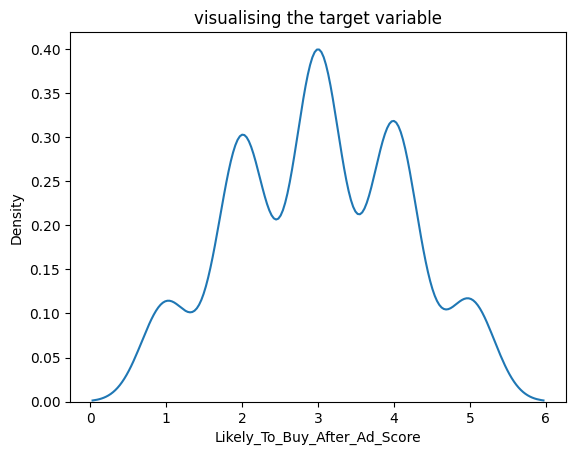

In [696]:
# visualising the target variable

sns.kdeplot(data=df, x=df['Likely_To_Buy_After_Ad_Score'])
plt.title('visualising the target variable')
plt.show()

In [697]:
df['Best_Shopping_Mode'].value_counts()

,count
Best_Shopping_Mode,
Online,218
Offline,118
Equal / both,113


In [698]:
df['Country_Region'].value_counts()

,count
Country_Region,
India,66
United States,56
Brazil,38
Mexico,35
Kenya,26
Indonesia,26
Egypt,25
Philippines,23
Nigeria,23


In [699]:
target = "Likely_To_Buy_After_Ad_Score"

groups = [
    "Age", "Gender", "Occupation_Status", "Country_Region",
    "Monthly_Income_Range", "Preferred_Platform",
    "Top_Spending_Category", "Best_Shopping_Mode"
]

for col in groups:
    result = (df.groupby(col, dropna=False)[target]
                .agg(["count", "mean"])
                .query("count >= 10")
                .sort_values("mean", ascending=False))
    print(f"\n{col}\n{result}")


Age
     count      mean
Age                 
30      12  3.583333
25      12  3.500000
23      18  3.388889
31      14  3.357143
19      27  3.333333
22      30  3.266667
20      45  3.222222
18      44  3.204545
24      20  3.100000
NaN     20  3.050000
26      11  3.000000
16      18  2.944444
17      13  2.923077
21      66  2.893939
29      12  2.750000
32      14  2.500000

Gender
                   count      mean
Gender                            
Male                 245  3.057143
Female               170  3.000000
Prefer not to say     46  2.934783
NaN                   14  2.785714

Occupation_Status
                    count      mean
Occupation_Status                  
NaN                    20  3.200000
Student               228  3.114035
Employed part-time     65  2.969231
Employed full-time    112  2.955357
Unemployed             18  2.722222
Self-employed          32  2.687500

Country_Region
                count      mean
Country_Region                 
NaN         

In [700]:
df

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,18/07/2026 23:18:07,42,Female,Employed full-time,India,"$1,000-3,000",Online only,Often,Global marketplace (Amazon etc.),...,Never,Under $50,Digital wallet,"Yes, regularly",4.0,5.0,2.0,More variety,Try product before buying,Online
496,497,28/06/2026 15:20:50,22,Prefer not to say,NaN,Colombia,"Under $1,000",Online only,Occasionally,Global marketplace (Amazon etc.),...,Often,Under $50,Digital wallet,"No, never",9.0,5.0,2.0,More variety,Try product before buying,Equal / both
497,498,23/06/2026 05:27:31,26,Male,Student,Brazil,NaN,Equal mix,Often,Brand websites,...,Never,$150-300,Digital wallet,"No, never",8.0,5.0,1.0,Better prices,Trust,Offline
498,499,17/07/2026 08:05:20,37,Female,Employed full-time,United Kingdom,"$6,000+",In-store only,Occasionally,Global marketplace (Amazon etc.),...,Never,$50-150,Digital wallet,"No, never",8.0,10.0,2.0,More variety,Trust,Offline


# Analytical Questions

1. The online shopping mode is more dominant when compare to offline and both

2. The people from the region of india is dominating the survey

3. We can able to identify that contry india , gender male, Student, Under 1,000 , Global marketplace, Clothing and online has the highest people dominating  the survy and most of the people in india has an income of below $1000 income and they prefer bying clothing from online marketing and it has 500 rows of 30 columns

# Task 2: Data Preprocessing


In [701]:
# handling missing values

df.isnull().sum()


,0
Response_ID,0
Timestamp,0
Age,22
Gender,16
Occupation_Status,21
Country_Region,20
Monthly_Income_Range,21
Shop_Most_Where,16
Online_Shopping_Frequency,19
Preferred_Platform,14


In [702]:
df.columns

Index(['Response_ID', 'Timestamp', 'Age', 'Gender', 'Occupation_Status',
       'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where',
       'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device',
       'Top_Spending_Category', 'Review_Influence_Score',
       'Social_Ads_Influence_Score', 'Price_Comparison_Frequency',
       'Discount_Importance_Score', 'Follows_Brands_On_Social',
       'Likely_To_Buy_After_Ad_Score', 'Makes_Shopping_List',
       'Impulse_Purchase_Frequency', 'Return_Frequency',
       'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method',
       'Uses_BNPL_Installments', 'Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode'],
      dtype='object')

In [703]:
# converting age to int

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

In [704]:
columns = ['Age', 'Gender', 'Occupation_Status',
       'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where',
       'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device',
       'Top_Spending_Category', 'Follows_Brands_On_Social',
        'Makes_Shopping_List',
        'Return_Frequency',
       'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method',
       'Uses_BNPL_Installments','Reason_Prefer_Online', 'Reason_Prefer_InStore',
        'Best_Shopping_Mode',
       ]

for col in categerical_coumns:
    print(df[col].value_counts())

Gender
Male                 256
Female               177
Prefer not to say     51
Name: count, dtype: int64
Occupation_Status
Student               238
Employed full-time    118
Employed part-time     71
Self-employed          33
Unemployed             19
Name: count, dtype: int64
Country_Region
India             66
United States     56
Brazil            38
Mexico            35
Kenya             26
Indonesia         26
Egypt             25
Philippines       23
Nigeria           23
United Kingdom    23
Pakistan          23
Colombia          21
Vietnam           20
South Africa      20
Turkiye           19
Poland            19
Germany           11
Slovakia           6
Name: count, dtype: int64
Monthly_Income_Range
Under $1,000    257
$1,000-3,000    122
$3,000-6,000     65
$6,000+          35
Name: count, dtype: int64
Shop_Most_Where
Equal mix        248
Online only      165
In-store only     71
Name: count, dtype: int64
Online_Shopping_Frequency
Occasionally    240
Often           132
R

In [705]:
categorical_columns = [
        "Age", "Gender", "Occupation_Status", "Country_Region",
        "Monthly_Income_Range", "Shop_Most_Where",
        "Online_Shopping_Frequency", "Preferred_Platform",
        "Primary_Device", "Top_Spending_Category",
        "Follows_Brands_On_Social", "Makes_Shopping_List",
        "Return_Frequency", "Avg_Monthly_Spend_NonEssentials",
        "Preferred_Payment_Method", "Uses_BNPL_Installments",
        "Reason_Prefer_Online", "Reason_Prefer_InStore",
        "Best_Shopping_Mode"
    ]

for col in categorical_columns:
    df[col] = df[col].fillna(
        df[col].mode().iloc[0]
        if not df[col].mode().empty
        else "Unknown"
    )

In [706]:
df.isnull().sum()

,0
Response_ID,0
Timestamp,0
Age,0
Gender,0
Occupation_Status,0
Country_Region,0
Monthly_Income_Range,0
Shop_Most_Where,0
Online_Shopping_Frequency,0
Preferred_Platform,0


In [707]:
categorical_columns = [
         "Gender", "Occupation_Status", "Country_Region",
        "Monthly_Income_Range", "Shop_Most_Where",
        "Online_Shopping_Frequency", "Preferred_Platform",
        "Primary_Device", "Top_Spending_Category",
        "Follows_Brands_On_Social", "Makes_Shopping_List",
        "Return_Frequency", "Avg_Monthly_Spend_NonEssentials",
        "Preferred_Payment_Method", "Uses_BNPL_Installments",
        "Reason_Prefer_Online", "Reason_Prefer_InStore",
        "Best_Shopping_Mode"
    ]

for col in categorical_columns:
    df[col] = df[col].fillna(
        df[col].mode().iloc[0]
        if not df[col].mode().empty
        else "Unknown"
    )

In [708]:
target = "Likely_To_Buy_After_Ad_Score"

numeric_columns = df.select_dtypes(include="number").columns
numeric_features = [col for col in numeric_columns if col != target]

for col in numeric_features:
    df[col] = df[col].fillna(df[col].median())

In [709]:
df.dropna(subset=["Likely_To_Buy_After_Ad_Score"],inplace = True)

In [710]:
df.isnull().sum()

,0
Response_ID,0
Timestamp,0
Age,0
Gender,0
Occupation_Status,0
Country_Region,0
Monthly_Income_Range,0
Shop_Most_Where,0
Online_Shopping_Frequency,0
Preferred_Platform,0


In [711]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
df["Best_Shopping_Mode"] = encoder.fit_transform(
    df["Best_Shopping_Mode"].astype(str)
)

In [712]:
# preparing the dataset for machine learning

from sklearn.model_selection import train_test_split

y = df["Best_Shopping_Mode"]
x = df.drop(columns=["Best_Shopping_Mode",'Response_ID','Timestamp'])

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size= 0.2 , random_state = 42)


In [713]:
x_train

,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,Primary_Device,Top_Spending_Category,...,Impulse_Purchase_Frequency,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore
255,17.0,Male,Student,Egypt,"Under $1,000",Equal mix,Occasionally,Brand websites,Smartphone,Clothing,...,2.0,Never,$300-500,Credit Card,"Yes, occasionally",7.0,3.0,2.0,More variety,Trust
219,31.0,Male,Employed part-time,India,"Under $1,000",In-store only,Always,Global marketplace (Amazon etc.),Smartphone,Groceries,...,1.0,Sometimes,Under $50,Cash,"No, never",6.0,6.0,3.0,More variety,Try product before buying
247,22.0,Female,Student,Indonesia,"$1,000-3,000",Equal mix,Occasionally,Physical stores,Laptop,Clothing,...,2.0,Sometimes,$150-300,Cash,"No, never",7.0,6.0,2.0,More variety,Try product before buying
419,20.0,Male,Student,India,"Under $1,000",Online only,Occasionally,Physical stores,Smartphone,Clothing,...,4.0,Never,Under $50,Credit Card,"No, never",6.0,6.0,3.0,Convenience,Try product before buying
22,21.0,Female,Student,India,"Under $1,000",Online only,Occasionally,Brand websites,Smartphone,miscellaneous,...,2.0,Never,$50-150,Digital wallet,"Yes, occasionally",7.0,6.0,3.0,Not applicable,Try product before buying
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,19.0,Female,Student,Philippines,"Under $1,000",In-store only,Often,Local e-commerce,Smartphone,Groceries,...,2.0,Never,$50-150,Digital wallet,"Yes, occasionally",7.0,7.0,3.0,Better prices,Trust
289,18.0,Female,Student,Egypt,"Under $1,000",Online only,Occasionally,Global marketplace (Amazon etc.),Smartphone,Clothing,...,4.0,Never,Under $50,Credit Card,"Yes, regularly",7.0,7.0,1.0,More variety,Try product before buying
368,36.0,Female,Employed full-time,Nigeria,"Under $1,000",Equal mix,Often,Brand websites,Smartphone,Electronics,...,3.0,Often,$150-300,Digital wallet,"No, never",6.0,10.0,2.0,More variety,Trust
458,34.0,Female,Employed part-time,Germany,"Under $1,000",Equal mix,Occasionally,Local e-commerce,Smartphone,miscellaneous,...,5.0,Often,Under $50,Credit Card,"Yes, occasionally",7.0,7.0,4.0,More variety,Trust


In [714]:
x_test

,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,Primary_Device,Top_Spending_Category,...,Impulse_Purchase_Frequency,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore
395,44.0,Female,Employed full-time,Brazil,"$1,000-3,000",Equal mix,Often,Local e-commerce,Smartphone,Clothing,...,1.0,Sometimes,$50-150,Debit Card,"Yes, regularly",7.0,6.0,2.0,More variety,Try product before buying
445,22.0,Male,Student,India,"Under $1,000",Equal mix,Occasionally,Brand websites,Smartphone,Clothing,...,1.0,Never,$150-300,Digital wallet,"No, never",4.0,5.0,2.0,More variety,Not applicable
9,20.0,Female,Student,Brazil,"Under $1,000",Equal mix,Rarely,Physical stores,Smartphone,Electronics,...,4.0,Sometimes,$150-300,Digital wallet,"Yes, regularly",7.0,8.0,2.0,More variety,No delivery wait
80,21.0,Female,Employed full-time,Vietnam,"$6,000+",Online only,Occasionally,Local e-commerce,Smartphone,Electronics,...,2.0,Never,$500+,Credit Card,"Yes, occasionally",10.0,6.0,1.0,Convenience,Trust
374,18.0,Female,Employed part-time,Indonesia,"$1,000-3,000",Online only,Occasionally,Global marketplace (Amazon etc.),Laptop,Beauty & personal care,...,1.0,Never,Under $50,Digital wallet,"Yes, occasionally",8.0,3.0,1.0,More variety,Trust
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
439,20.0,Male,Student,Kenya,"$1,000-3,000",Equal mix,Occasionally,Physical stores,Smartphone,Electronics,...,2.0,Often,$300-500,Digital wallet,"No, never",6.0,7.0,3.0,More variety,Try product before buying
44,27.0,Male,Employed part-time,Turkiye,"$1,000-3,000",Equal mix,Occasionally,Global marketplace (Amazon etc.),Laptop,Groceries,...,1.0,Often,$50-150,Debit Card,"Yes, occasionally",6.0,4.0,1.0,Convenience,Trust
215,37.0,Prefer not to say,Employed part-time,Brazil,"Under $1,000",Equal mix,Rarely,Local e-commerce,Smartphone,Clothing,...,3.0,Never,Under $50,Debit Card,"No, never",5.0,8.0,2.0,Convenience,Not applicable
166,19.0,Male,Student,India,"$1,000-3,000",Online only,Occasionally,Local e-commerce,Smartphone,Clothing,...,4.0,Never,$300-500,Credit Card,"No, never",8.0,7.0,4.0,More variety,Try product before buying


In [715]:
import pandas as np  # Not needed
import pandas as pd
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import OneHotEncoder

categorical_columns = x_train.select_dtypes(
    include=["object", "category"]
).columns

encoder = OneHotEncoder(handle_unknown="ignore")

x_train_cat = encoder.fit_transform(x_train[categorical_columns])
x_test_cat = encoder.transform(x_test[categorical_columns])

cat_feature_names = encoder.get_feature_names_out(categorical_columns)

x_train = pd.DataFrame(
    x_train_cat.toarray(),
  columns=cat_feature_names,
    index=x_train.index
).join(
    x_train.drop(columns=categorical_columns)
)

x_test= pd.DataFrame(
    x_test_cat.toarray(),
    columns=cat_feature_names,
    index=x_test.index
).join(
    x_test.drop(columns=categorical_columns)
)

In [716]:
# using std scaling

from sklearn.preprocessing import StandardScaler

numeric_columns = x_train.select_dtypes(include="number").columns

scaler = StandardScaler()

x_train[numeric_columns] = scaler.fit_transform(
    x_train[numeric_columns]
)

x_test[numeric_columns] = scaler.transform(
    x_test[numeric_columns]
)

1. Preprocessing decisions are more important because they determine whether the model learns meaningful patterns rather than noise, labels, or inconsistent scales

2. Improper preprocessing can make predictions biased, inaccurate, or misleading

# Task 3: Exlpotary data analysis

In [717]:
df.columns

Index(['Response_ID', 'Timestamp', 'Age', 'Gender', 'Occupation_Status',
       'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where',
       'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device',
       'Top_Spending_Category', 'Review_Influence_Score',
       'Social_Ads_Influence_Score', 'Price_Comparison_Frequency',
       'Discount_Importance_Score', 'Follows_Brands_On_Social',
       'Likely_To_Buy_After_Ad_Score', 'Makes_Shopping_List',
       'Impulse_Purchase_Frequency', 'Return_Frequency',
       'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method',
       'Uses_BNPL_Installments', 'Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode'],
      dtype='object')

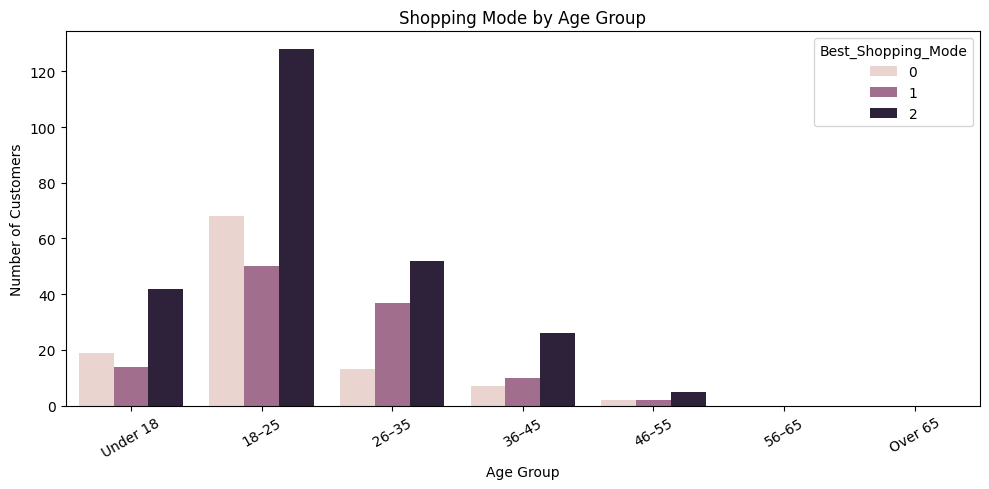

In [718]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 18, 25, 35, 45, 55, 65, float("inf")],
    labels=["Under 18", "18–25", "26–35", "36–45", "46–55", "56–65", "Over 65"]
)

plot_df = df.dropna(subset=["Age_Group", "Best_Shopping_Mode"])

plt.figure(figsize=(10, 5))
sns.countplot(
    data=plot_df,
    x="Age_Group",
    hue="Best_Shopping_Mode"
)
plt.title("Shopping Mode by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

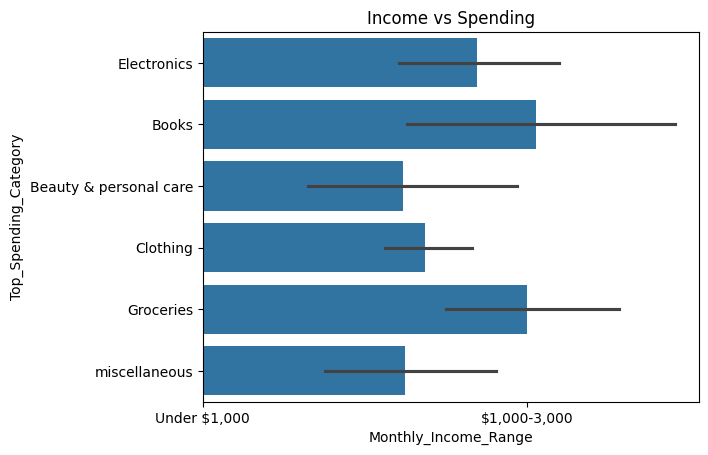

In [719]:
# for Income vs Spending

sns.barplot(data=df,x='Monthly_Income_Range',y='Top_Spending_Category',orient='h')
plt.title("Income vs Spending")
plt.show()

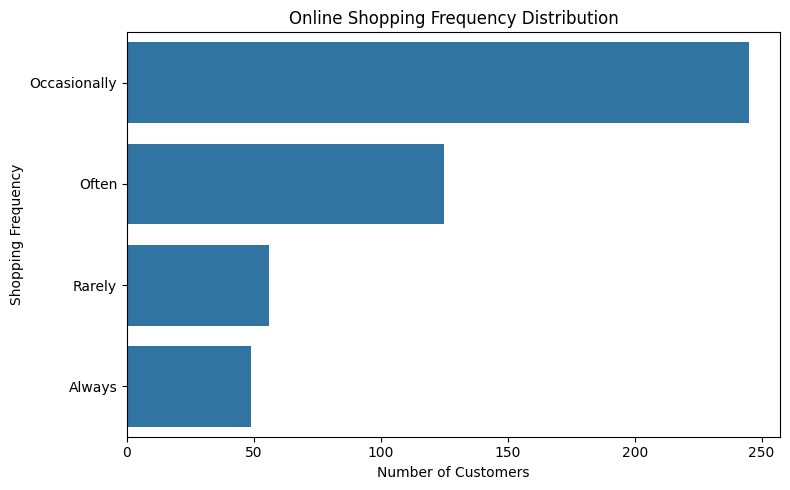

In [720]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    y="Online_Shopping_Frequency",
    order=df["Online_Shopping_Frequency"].value_counts().index
)
plt.title("Online Shopping Frequency Distribution")
plt.xlabel("Number of Customers")
plt.ylabel("Shopping Frequency")
plt.tight_layout()
plt.show()

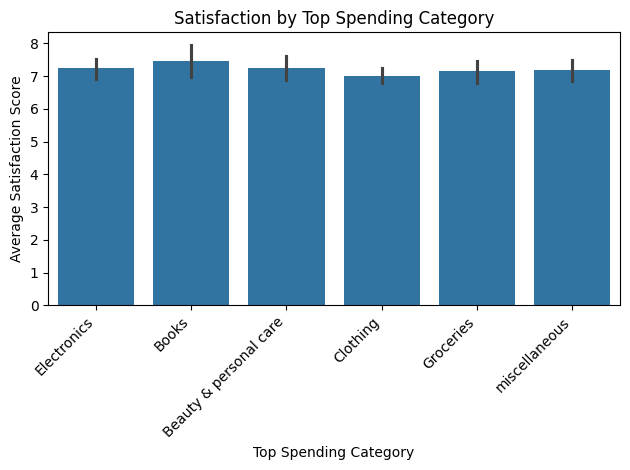

In [721]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(
    data=df,
    x="Top_Spending_Category",
    y="Online_Shopping_Satisfaction_Score",
    estimator="mean",
    orient="v"
)

plt.title("Satisfaction by Top Spending Category")
plt.xlabel("Top Spending Category")
plt.ylabel("Average Satisfaction Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

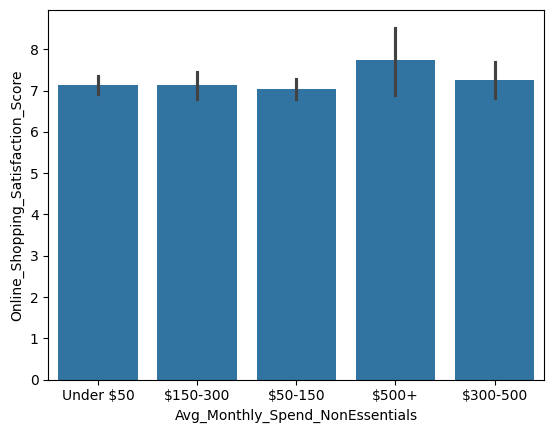

In [722]:
# Average satisfaction by monthly spending category
sns.barplot(data=df,x="Avg_Monthly_Spend_NonEssentials",y="Online_Shopping_Satisfaction_Score",)
plt.show()

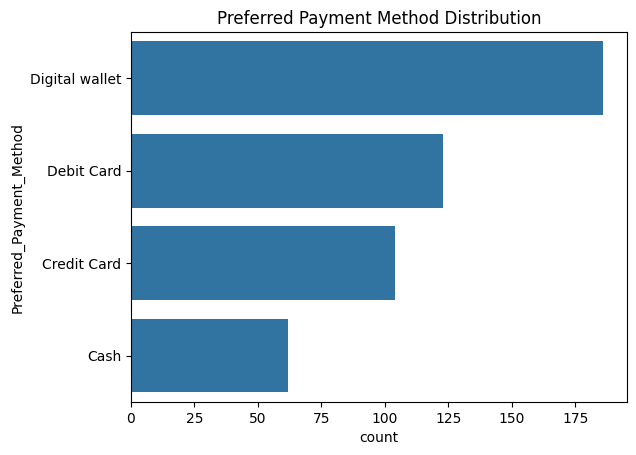

In [723]:
# Payment method distribution
sns.countplot(data=df,y="Preferred_Payment_Method",order=df["Preferred_Payment_Method"].value_counts().index)
plt.title("Preferred Payment Method Distribution")
plt.show()

In [724]:
# Analytical Questions

1. The age group from 18 to 25 and the income of 1000 -3000 range affects the online shopping
2. Higher income people tends to spend more on shopping
3. Higher satisfaction: Customers who prefer that mode are generally more positive about online shopping.

# Task 4 Machine Learning

In [725]:
# Keep enough principal components to explain 95% of training variance
from sklearn.decomposition import PCA
pca = PCA(n_components=0.95, random_state=42)
x_train = pca.fit_transform(x_train)
x_test = pca.transform(x_test)

print("Features before PCA:", x_train.shape[1])
print("Components retained:", pca.n_components_)
print("Variance explained:", round(pca.explained_variance_ratio_.sum(), 3))

Features before PCA: 63
Components retained: 63
Variance explained: 0.956


In [726]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(x_train, y_train)

y_pred_lr = lr_model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred_lr)
cm = confusion_matrix(y_test, y_pred_lr)

print("Accuracy:", accuracy)
print("Confusion matrix:\n", cm)

Accuracy: 0.5894736842105263
Confusion matrix:
 [[ 4  5 10]
 [ 7 15  8]
 [ 2  7 37]]


In [733]:
# Random forest regressor

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score


rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(x_train, y_train)
y_pred_rf = rf_model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred_rf)
cm = confusion_matrix(y_test, y_pred_rf)

print("Accuracy:", accuracy)
print("Confusion matrix:\n", cm)

Accuracy: 0.49473684210526314
Confusion matrix:
 [[ 0  0 19]
 [ 2  1 27]
 [ 0  0 46]]


accuracy = accuracy_score(y_test, y_pred_lr)
cm = confusion_matrix(y_test, y_pred_lr)

print("Accuracy:", accuracy)
print("Confusion matrix:\n", cm)

In [734]:
from xgboost import XGBClassifier
from sklearn.metrics import mean_squared_error, r2_score

xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42
)

xgb_model.fit(x_train, y_train)
y_pred_xgb = xgb_model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred_lr)
cm = confusion_matrix(y_test, y_pred_lr)

print("Accuracy:", accuracy)
print("Confusion matrix:\n", cm)

Accuracy: 0.5368421052631579
Confusion matrix:
 [[ 2  2 15]
 [ 6  9 15]
 [ 4  2 40]]


In [735]:
# lightgbm

from lightgbm import LGBMClassifier
from sklearn.metrics import mean_squared_error, r2_score

lgbm_model = LGBMClassifier(
    n_estimators=100,
    random_state=42
)

lgbm_model.fit(
    x_train,
    y_train,
    feature_name="auto"
)
y_pred_lgbm = lgbm_model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred_lgbm)
cm = confusion_matrix(y_test, y_pred_lgbm)

print("Accuracy:", accuracy)
print("Confusion matrix:\n", cm)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000405 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 8028
[LightGBM] [Info] Number of data points in the train set: 380, number of used features: 63
[LightGBM] [Info] Start training from score -1.440362
[LightGBM] [Info] Start training from score -1.521331
[LightGBM] [Info] Start training from score -0.607452
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No fu

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


# Analytical Questions

1. Linear Regressor is the best performasnce as it has lowest RMSE and highest R2 model
2. All the features are necessary to make it when we use pca it retained all the features
3. Possible explanations to check include outliers, sparse categories, unseen categories (the encoder ignores unknown values), and patterns the linear model can’t capture, such as nonlinear effects or interactions. These are possibilities, not confirmed causes without the evaluation data.

In [736]:
import joblib

# Bundle the trained regression artifacts together using your actual best tuned objects
pipeline_package = {
    "scaler": scaler,
    "encoder": encoder,
    "model": lr_model,
    "feature_names": x_train.tolist(),
}

joblib.dump(pipeline_package, "machine_learning_bundle.pkl")

['machine_learning_bundle.pkl']